# Real vs AI-Generated Face Detection

**Team:** Kashmala Saghar (23K-3034), Manahil Ayaz (23K-3018)

This notebook is a self-contained, end-to-end version of the project for Colab's free GPU.
It downloads the **140k Real and Fake Faces** dataset, trains a custom CNN and a fine-tuned
MobileNetV2, evaluates both on the test set, explains predictions with Grad-CAM, and launches
a Gradio demo.

**Before running:** go to Runtime -> Change runtime type -> select a GPU.

Steps:
1. Install packages
2. Upload your Kaggle API key and download the dataset
3. Explore the data (EDA)
4. Build the data pipeline
5. Define the models
6. Train the custom CNN
7. Train MobileNetV2 (head, then fine-tune)
8. Evaluate both models on the test set
9. Grad-CAM explanations
10. Gradio demo (public link)


## 1. Install packages

In [3]:
!pip install -q kaggle gradio opencv-python-headless


## 2. Mount Google Drive (for checkpoint recovery)

Colab's local disk (`/content/...`) is wiped every time the runtime disconnects, so
anything saved only there -- including model checkpoints -- is lost. Mounting Drive
here means `MODELS_DIR` and the per-epoch resume state below live on your Drive
instead. If training disconnects, just reconnect the runtime and re-run the training
cell (same `epochs` value): it resumes from the last completed epoch instead of
starting over, and `models/` on Drive keeps whatever was already saved.


In [4]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = "/content/drive/MyDrive/ai-face-detector"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Download the dataset

Get your Kaggle API key from Kaggle -> Settings -> API -> Create New Token. This downloads
`kaggle.json`. Run the cell below and upload that file when prompted.


In [6]:
import os
from google.colab import files

os.makedirs("/root/.kaggle", exist_ok=True)
uploaded = files.upload()  # choose your kaggle.json
for fname in uploaded:
    os.rename(fname, "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)


Saving kaggle.json to kaggle.json


In [4]:
!kaggle datasets download -d xhlulu/140k-real-and-fake-faces -p /content/data --unzip


Dataset URL: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces
License(s): other
100% 3.75G/3.75G [00:41<00:00, 96.5MB/s]



In [7]:
DATA_DIR = "/content/data/real_vs_fake/real-vs-fake"  # re-downloaded each session, not persisted
MODELS_DIR = os.path.join(DRIVE_DIR, "models")  # on Drive so it survives disconnects
FIGURES_DIR = os.path.join(DRIVE_DIR, "outputs", "figures")
METRICS_DIR = os.path.join(DRIVE_DIR, "outputs", "metrics")
BACKUP_DIR = os.path.join(DRIVE_DIR, "backup")  # per-epoch resume state (optimizer + epoch number)

import os
for d in (MODELS_DIR, FIGURES_DIR, METRICS_DIR, BACKUP_DIR):
    os.makedirs(d, exist_ok=True)

SEED = 42
CNN_IMG_SIZE = (128, 128)
TL_IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS_CNN = 15
EPOCHS_TL_HEAD = 8
EPOCHS_TL_FINETUNE = 5
TRAIN_SUBSET = None  # use the full dataset for the real run

import tensorflow as tf
import numpy as np
import random

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(tf.__version__, tf.config.list_physical_devices("GPU"))


2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 4. Explore the data (EDA)

Quick sanity check: count images per split/class, plot the class balance, and look at a
sample grid of faces before training anything.


{
  "train": {
    "fake": 50000,
    "real": 50000
  },
  "valid": {
    "fake": 10000,
    "real": 10000
  },
  "test": {
    "fake": 10000,
    "real": 10000
  }
}


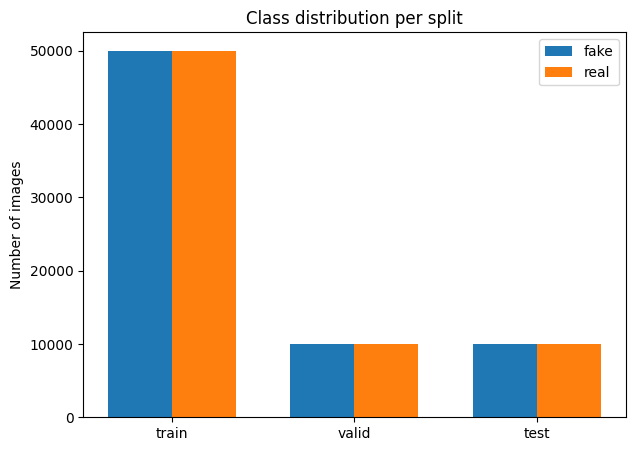

In [ ]:
import json as _json
import cv2
import matplotlib.pyplot as plt

SPLITS = ["train", "valid", "test"]
CLASSES = ["fake", "real"]

counts = {}
for split in SPLITS:
    counts[split] = {}
    for cls in CLASSES:
        folder = os.path.join(DATA_DIR, split, cls)
        counts[split][cls] = len(
            [f for f in os.listdir(folder) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        )

print(_json.dumps(counts, indent=2))
with open(os.path.join(METRICS_DIR, "dataset_counts.json"), "w") as f:
    _json.dump(counts, f, indent=2)

fig, ax = plt.subplots(figsize=(7, 5))
x = range(len(SPLITS))
width = 0.35
ax.bar([i - width / 2 for i in x], [counts[s]["fake"] for s in SPLITS], width, label="fake")
ax.bar([i + width / 2 for i in x], [counts[s]["real"] for s in SPLITS], width, label="real")
ax.set_xticks(list(x))
ax.set_xticklabels(SPLITS)
ax.set_ylabel("Number of images")
ax.set_title("Class distribution per split")
ax.legend()
fig.savefig(os.path.join(FIGURES_DIR, "class_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()


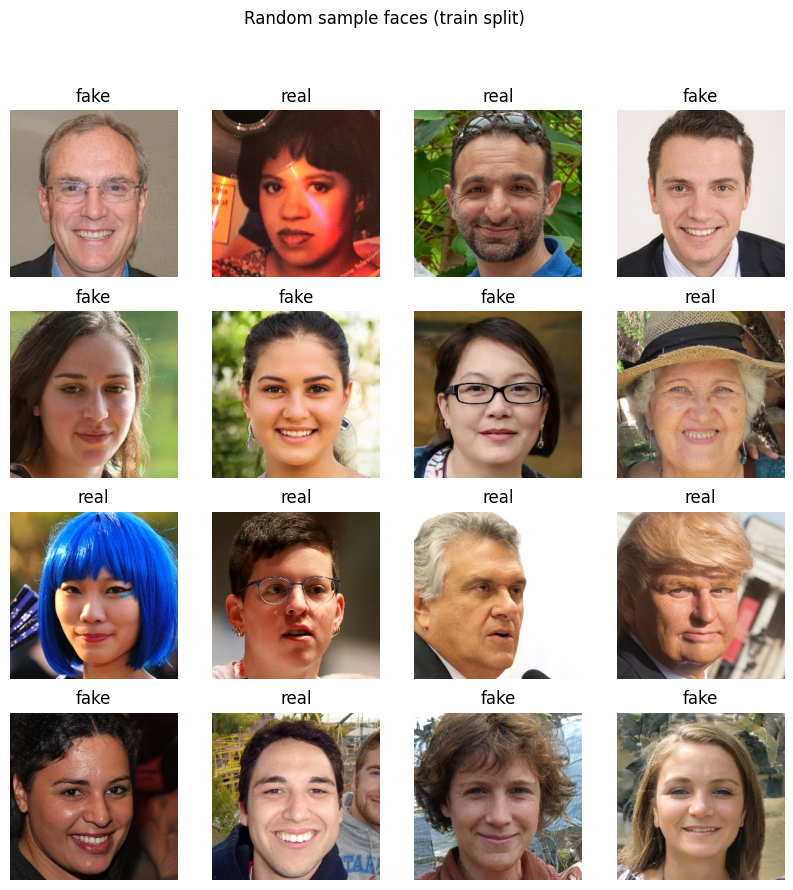

In [ ]:
samples = []
for cls in CLASSES:
    folder = os.path.join(DATA_DIR, "train", cls)
    files_ = random.sample(os.listdir(folder), 8)
    samples.extend((os.path.join(folder, f), cls) for f in files_)
random.shuffle(samples)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, (path, label) in zip(axes.flat, samples):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(label)
    ax.axis("off")
fig.suptitle("Random sample faces (train split)")
fig.savefig(os.path.join(FIGURES_DIR, "sample_grid.png"), dpi=150, bbox_inches="tight")
plt.show()


## 5. Data pipeline

Loads each split with `image_dataset_from_directory`. Classes are alphabetical, so
**fake = 0, real = 1** -- the model's sigmoid output is P(real). Augmentation (flip,
rotation, brightness, contrast) is applied to the training set only.


In [8]:
from tensorflow.keras import layers

AUGMENTATION = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")


def _load_split(split, img_size, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(DATA_DIR, split),
        label_mode="binary",
        image_size=img_size,
        batch_size=BATCH_SIZE,
        seed=SEED,
        shuffle=shuffle,
    )


def get_datasets(img_size, preprocess=None):
    train_ds = _load_split("train", img_size, shuffle=True)
    val_ds = _load_split("valid", img_size, shuffle=False)
    test_ds = _load_split("test", img_size, shuffle=False)

    class_names = train_ds.class_names
    print("class_names:", class_names)

    if TRAIN_SUBSET:
        train_ds = train_ds.unbatch().take(TRAIN_SUBSET).batch(BATCH_SIZE)

    train_ds = train_ds.map(lambda x, y: (AUGMENTATION(x, training=True), y),
                             num_parallel_calls=tf.data.AUTOTUNE)

    if preprocess is not None:
        train_ds = train_ds.map(lambda x, y: (preprocess(x), y), num_parallel_calls=tf.data.AUTOTUNE)
        val_ds = val_ds.map(lambda x, y: (preprocess(x), y), num_parallel_calls=tf.data.AUTOTUNE)
        test_ds = test_ds.map(lambda x, y: (preprocess(x), y), num_parallel_calls=tf.data.AUTOTUNE)

    train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
    val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
    test_ds = test_ds.prefetch(tf.data.AUTOTUNE)
    return train_ds, val_ds, test_ds, class_names


## 6. Models

**Custom CNN:** 4 Conv/BatchNorm/MaxPool blocks (32/64/128/256 filters) -> GlobalAveragePooling2D
-> Dense(128) -> Dropout(0.5) -> sigmoid.

**MobileNetV2:** ImageNet weights, frozen at first, built functionally so `Conv_1` is directly
reachable for Grad-CAM -> GlobalAveragePooling2D -> Dropout(0.3) -> sigmoid.


In [9]:
from tensorflow.keras import models as kmodels

METRICS = [
    "accuracy",
    tf.keras.metrics.Precision(name="precision"),
    tf.keras.metrics.Recall(name="recall"),
    tf.keras.metrics.AUC(name="auc"),
]


def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy", metrics=METRICS)
    return model


def build_cnn(lr=1e-3):
    inputs = layers.Input(shape=CNN_IMG_SIZE + (3,))
    x = layers.Rescaling(1.0 / 255)(inputs)
    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = kmodels.Model(inputs, outputs, name="custom_cnn")
    return compile_model(model, lr)


MOBILENET_HEAD_LAYERS = 3  # GlobalAveragePooling2D, Dropout, Dense


def build_mobilenet(lr=1e-3):
    inputs = layers.Input(shape=TL_IMG_SIZE + (3,))
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
    base = tf.keras.applications.MobileNetV2(input_tensor=x, include_top=False, weights="imagenet")
    base.trainable = False
    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = kmodels.Model(inputs, outputs, name="mobilenet_v2_tl")
    return compile_model(model, lr)


def unfreeze_mobilenet_top(model, n_layers=30):
    base_layers = model.layers[:-MOBILENET_HEAD_LAYERS]
    for layer in base_layers:
        layer.trainable = True
    for layer in base_layers[:-n_layers]:
        layer.trainable = False
    for layer in base_layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    return model


## 7. Train the custom CNN

Trains for `EPOCHS_CNN` epochs with early stopping, checkpointing, LR reduction on plateau,
and a CSV log, then plots train vs validation accuracy/loss.

If the runtime disconnects, just reconnect and re-run this cell (same `epochs`) -- it
resumes from the last completed epoch instead of restarting.

**No GPU yet?** This cell is the only thing in the notebook that doesn't need one --
it trains in a CPU-only runtime too (just slower). You can run everything up through
this cell now and come back for Section 8 (MobileNetV2) once a GPU is available. The
next three sections (Evaluate / Grad-CAM / Gradio) also work with just the CNN -- they
skip whichever model isn't defined yet -- so you can look at CNN-only results now and
re-run those same cells later to add MobileNetV2 once it's trained.


In [ ]:
def make_callbacks(name, stage="main"):
    # `stage` keeps each fit() call's resume state separate (e.g. MobileNetV2's head vs.
    # finetune stages). Re-running the same training cell after a disconnect resumes from
    # the last completed epoch; `{name}_last.keras` is also a plain, independently loadable
    # fallback in case you just want the latest weights without resuming `fit()`.
    backup_dir = os.path.join(BACKUP_DIR, f"{name}_{stage}")
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, f"{name}_best.keras"),
                                            monitor="val_loss", save_best_only=True),
        tf.keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, f"{name}_last.keras"),
                                            save_best_only=False),
        tf.keras.callbacks.BackupAndRestore(backup_dir=backup_dir),
        tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2),
        tf.keras.callbacks.CSVLogger(os.path.join(METRICS_DIR, f"{name}_history.csv"), append=True),
    ]


def plot_curves(history_dicts, name):
    acc, val_acc, loss, val_loss = [], [], [], []
    for h in history_dicts:
        acc += h.get("accuracy", [])
        val_acc += h.get("val_accuracy", [])
        loss += h.get("loss", [])
        val_loss += h.get("val_loss", [])
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].plot(acc, label="train"); axes[0].plot(val_acc, label="val")
    axes[0].set_title(f"{name} accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(loss, label="train"); axes[1].plot(val_loss, label="val")
    axes[1].set_title(f"{name} loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
    fig.savefig(os.path.join(FIGURES_DIR, f"{name}_training_curves.png"), dpi=150, bbox_inches="tight")
    plt.show()


Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
class_names: ['fake', 'real']
class_names: ['fake', 'real']
Epoch 3/15
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 357s 109ms/step - accuracy: 0.8606 - auc: 0.9356 - loss: 0.3238 - precision: 0.8556 - recall: 0.8676 - val_accuracy: 0.8245 - val_auc: 0.9452 - val_loss: 0.3963 - val_precision: 0.7520 - val_recall: 0.9682 - learning_rate: 0.0010
Epoch 4/15
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 324s 104ms/step - accuracy: 0.8893 - auc: 0.9560 - loss: 0.2680 - precision: 0.8842 - recall: 0.8960 - val_accuracy: 0.8686 - val_auc: 0.9484 - val_loss: 0.3132 - val_precision: 0.8315 - val_recall: 0.9244 - learning_rate: 0.0010
Epoch 5/15
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 311s 100ms/step - accuracy: 0.9078 - auc: 0.9678 - loss: 0.2288 - precision: 0.9033 - recall: 0.9133 - val_accuracy: 0.9118 - val_auc: 0.9752 - val_loss: 0.2167 - val_precision: 0.9435 - val_recall: 0.8760 - learning_rate: 0.00

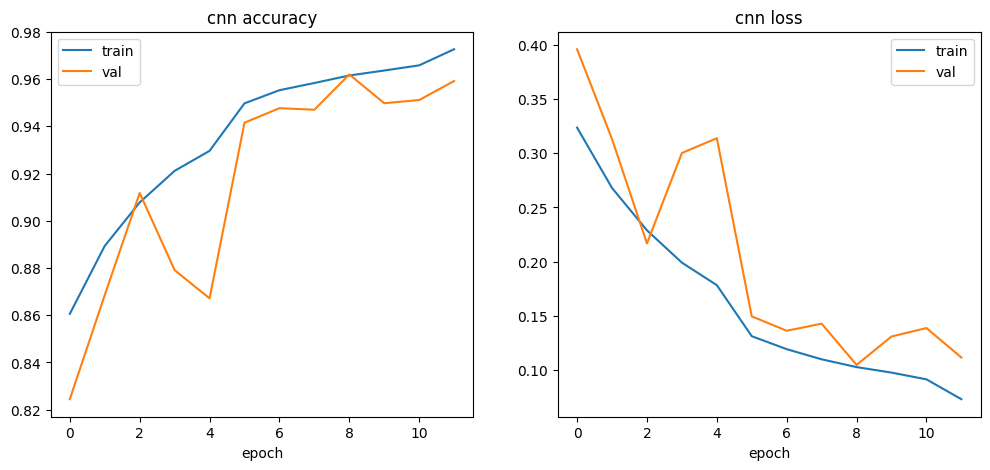

In [ ]:
cnn_train_ds, cnn_val_ds, cnn_test_ds, class_names = get_datasets(CNN_IMG_SIZE)
print("class_names:", class_names)  # fake=0, real=1

cnn_model = build_cnn(lr=1e-3)
cnn_history = cnn_model.fit(
    cnn_train_ds, validation_data=cnn_val_ds, epochs=EPOCHS_CNN, callbacks=make_callbacks("cnn", stage="main")
)
plot_curves([cnn_history.history], "cnn")


## 8. Train MobileNetV2 (transfer learning)

Stage 1 trains only the new head with the base frozen. Stage 2 unfreezes the top 30 base
layers (keeping BatchNorm frozen) and fine-tunes at a much lower learning rate.

Each stage has its own resume state, so a disconnect during either stage only re-runs
that stage's remaining epochs, not the whole thing.


In [12]:
tl_train_ds, tl_val_ds, tl_test_ds, class_names = get_datasets(TL_IMG_SIZE)

mobilenet_model = build_mobilenet(lr=1e-3)
head_history = mobilenet_model.fit(
    tl_train_ds, validation_data=tl_val_ds, epochs=EPOCHS_TL_HEAD, callbacks=make_callbacks("mobilenet", stage="head")
)


Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
class_names: ['fake', 'real']


/tmp/ipykernel_1472/172451840.py:38: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(input_tensor=x, include_top=False, weights="imagenet")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 782s 242ms/step - accuracy: 0.7242 - auc: 0.8514 - loss: 0.5442 - precision: 0.7671 - recall: 0.7563 - val_accuracy: 0.7786 - val_auc: 0.8610 - val_loss: 0.4762 - val_precision: 0.8091 - val_recall: 0.7291 - learning_rate: 0.0010
Epoch 2/8
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 781s 250ms/step - accuracy: 0.7434 - auc: 0.8194 - loss: 0.5225 - precision: 0.7510 - recall: 0.7283 - val_accuracy: 0.7731 - val_auc: 0.8654 - val_loss: 0.4805 - val_precision: 0.8498 - val_recall: 0.6634 - learning_rate: 0.0010
Epoch 3/8
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 773s 247ms/step - accuracy: 0.7429 - auc: 0.8191 - loss: 0.5234 - precision: 0.7502 - recall: 0.7282 - val_accuracy: 0.7855 - val_auc: 0.8653 - val_loss: 0.4686 - val_precision: 0.7947 - val_recall: 0.7699 - learning_rate: 0.0010
Epoch 4/8
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 793s 245ms/step - accuracy: 0.7422 - auc: 0.8173 - loss: 0.5258 - precision: 0.7501 - recall: 0.7

Epoch 1/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 830s 261ms/step - accuracy: 0.8150 - auc: 0.8917 - loss: 0.4035 - precision: 0.8149 - recall: 0.8026 - val_accuracy: 0.8784 - val_auc: 0.9537 - val_loss: 0.2867 - val_precision: 0.8580 - val_recall: 0.9070 - learning_rate: 1.0000e-05
Epoch 2/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 769s 246ms/step - accuracy: 0.8772 - auc: 0.9491 - loss: 0.2882 - precision: 0.8812 - recall: 0.8720 - val_accuracy: 0.8838 - val_auc: 0.9728 - val_loss: 0.2750 - val_precision: 0.8281 - val_recall: 0.9687 - learning_rate: 1.0000e-05
Epoch 3/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 940s 290ms/step - accuracy: 0.9032 - auc: 0.9668 - loss: 0.2331 - precision: 0.9067 - recall: 0.8990 - val_accuracy: 0.9165 - val_auc: 0.9804 - val_loss: 0.1995 - val_precision: 0.8854 - val_recall: 0.9568 - learning_rate: 1.0000e-05
Epoch 4/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 802s 257ms/step - accuracy: 0.9179 - auc: 0.9753 - loss: 0.2011 - precision: 0.9206 - recall: 0.9147 - val_accuracy: 0.9379 - val_auc:

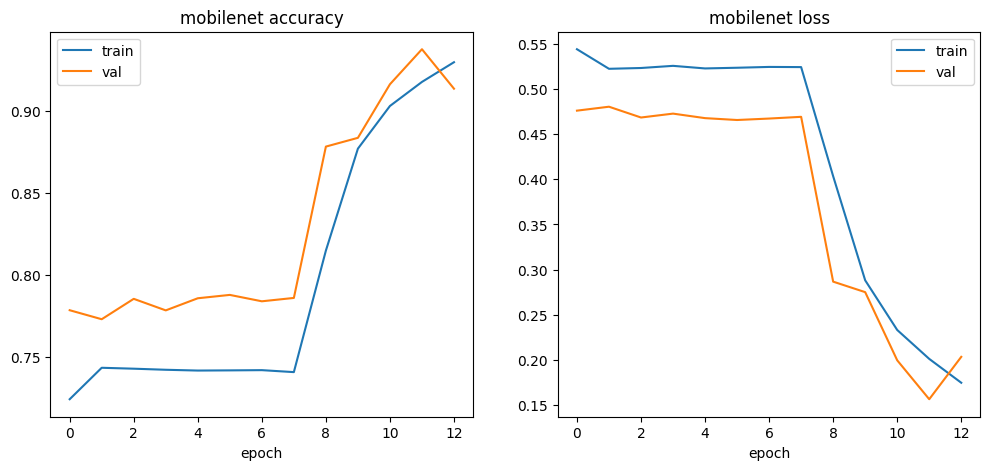

In [13]:
mobilenet_model = unfreeze_mobilenet_top(mobilenet_model, n_layers=30)
mobilenet_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
                         loss="binary_crossentropy", metrics=METRICS)
finetune_history = mobilenet_model.fit(
    tl_train_ds, validation_data=tl_val_ds, epochs=EPOCHS_TL_FINETUNE,
    callbacks=make_callbacks("mobilenet", stage="finetune")
)
plot_curves([head_history.history, finetune_history.history], "mobilenet")


## 9. Evaluate on the test set

For each model: classification report, confusion matrix, ROC/AUC, and a grid of
misclassified examples. Then a side-by-side comparison table and combined ROC plot.


In [10]:
cnn_model = tf.keras.models.load_model(os.path.join(MODELS_DIR, "cnn_best.keras"))
mobilenet_model = tf.keras.models.load_model(os.path.join(MODELS_DIR, "mobilenet_best.keras"))
_, _, cnn_test_ds, class_names = get_datasets(CNN_IMG_SIZE)
_, _, tl_test_ds, class_names = get_datasets(TL_IMG_SIZE)

Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
class_names: ['fake', 'real']
Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
class_names: ['fake', 'real']


In [11]:
import pandas as pd
import seaborn as sns
import time
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

CLASS_NAMES = ["fake", "real"]


def collect_predictions(model, test_ds):
    y_true, y_prob, images = [], [], []
    for x, y in test_ds:
        p = model.predict(x, verbose=0).flatten()
        y_true.append(y.numpy().flatten())
        y_prob.append(p)
        images.append(x.numpy())
    return np.concatenate(y_true), np.concatenate(y_prob), np.concatenate(images)


def evaluate_model(name, model, test_ds):
    y_true, y_prob, images = collect_predictions(model, test_ds)
    y_pred = (y_prob >= 0.5).astype(int)

    report_dict = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))
    with open(os.path.join(METRICS_DIR, f"{name}_report.json"), "w") as f:
        _json.dump(report_dict, f, indent=2)

    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{name} confusion matrix")
    fig.savefig(os.path.join(FIGURES_DIR, f"{name}_confusion_matrix.png"), dpi=150, bbox_inches="tight")
    plt.show()

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{name} ROC curve"); ax.legend()
    fig.savefig(os.path.join(FIGURES_DIR, f"{name}_roc.png"), dpi=150, bbox_inches="tight")
    plt.show()

    wrong_idx = np.where(y_pred != y_true)[0]
    n_show = min(8, len(wrong_idx))
    if n_show > 0:
        chosen = np.random.choice(wrong_idx, n_show, replace=False)
        fig, axes = plt.subplots(2, 4, figsize=(14, 7))
        for ax, idx in zip(axes.flat, chosen):
            ax.imshow(np.clip(images[idx] / 255.0, 0, 1))
            ax.set_title(f"true={CLASS_NAMES[int(y_true[idx])]}\npred={CLASS_NAMES[int(y_pred[idx])]} ({y_prob[idx]:.2f})")
            ax.axis("off")
        for ax in axes.flat[n_show:]:
            ax.axis("off")
        fig.savefig(os.path.join(FIGURES_DIR, f"{name}_errors.png"), dpi=150, bbox_inches="tight")
        plt.show()

    return {
        "model": name, "accuracy": report_dict["accuracy"],
        "precision_real": report_dict["real"]["precision"],
        "recall_real": report_dict["real"]["recall"],
        "f1_real": report_dict["real"]["f1-score"],
        "auc": roc_auc, "params": model.count_params(),
        "fpr": fpr, "tpr": tpr,
    }


In [12]:
import json as _json
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
import time
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc


In [13]:
def collect_predictions(model, test_ds):
    y_true, y_prob, images = [], [], []
    for x, y in test_ds:
        p = model.predict(x, verbose=0).flatten()
        y_true.append(y.numpy().flatten())
        y_prob.append(p)
        images.append(x.numpy().astype(np.uint8))  # 4x less RAM than default float32
    return np.concatenate(y_true), np.concatenate(y_prob), np.concatenate(images)

              precision    recall  f1-score   support

        fake       0.98      0.94      0.96     10000
        real       0.94      0.98      0.96     10000

    accuracy                           0.96     20000
   macro avg       0.96      0.96      0.96     20000
weighted avg       0.96      0.96      0.96     20000



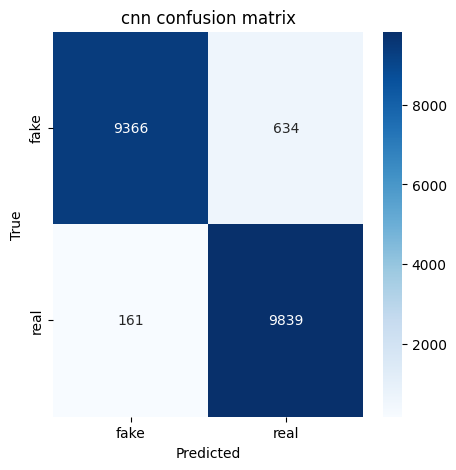

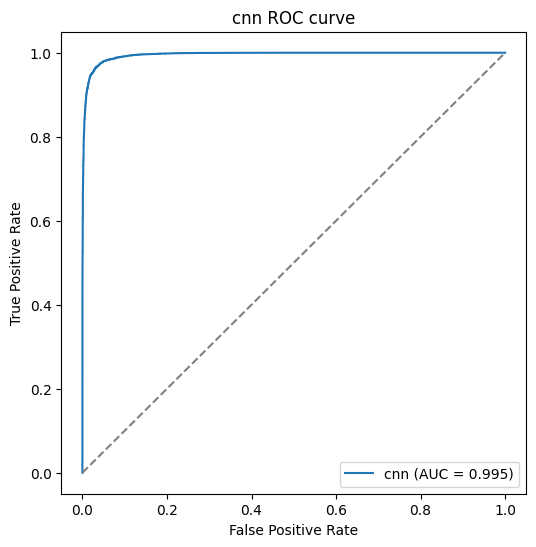

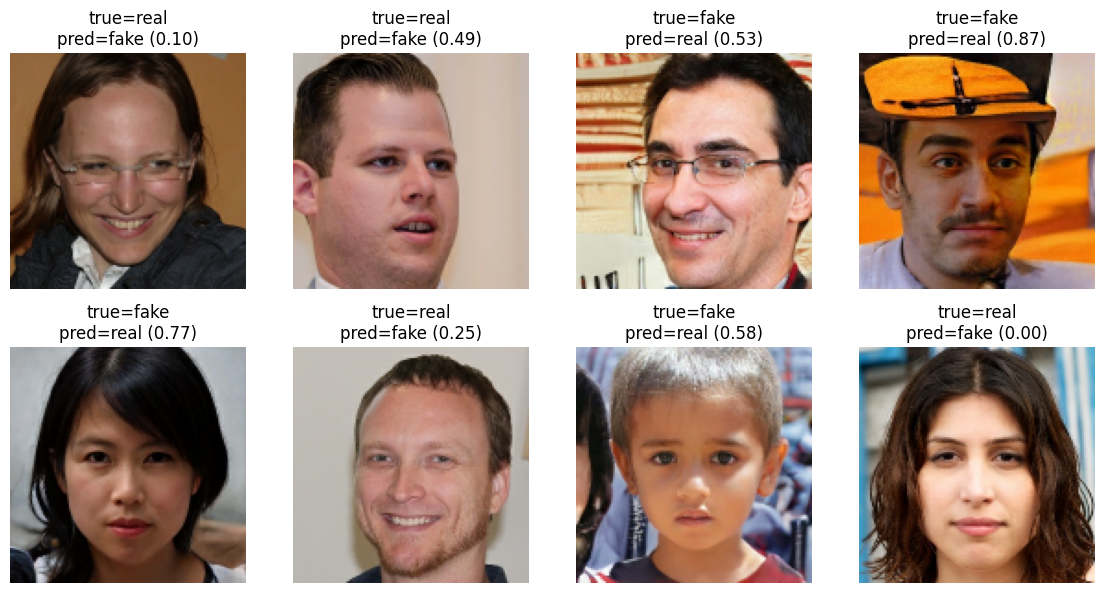

              precision    recall  f1-score   support

        fake       0.94      0.94      0.94     10000
        real       0.94      0.94      0.94     10000

    accuracy                           0.94     20000
   macro avg       0.94      0.94      0.94     20000
weighted avg       0.94      0.94      0.94     20000



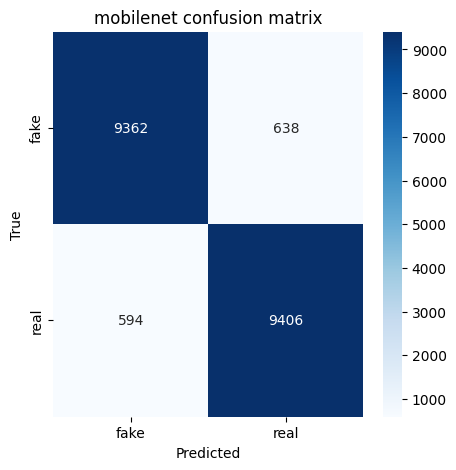

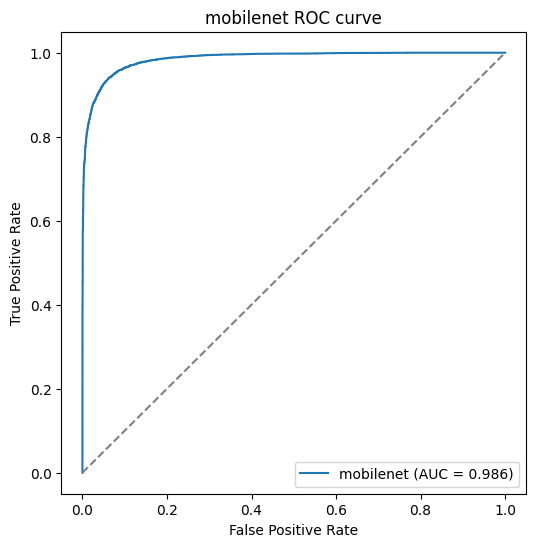

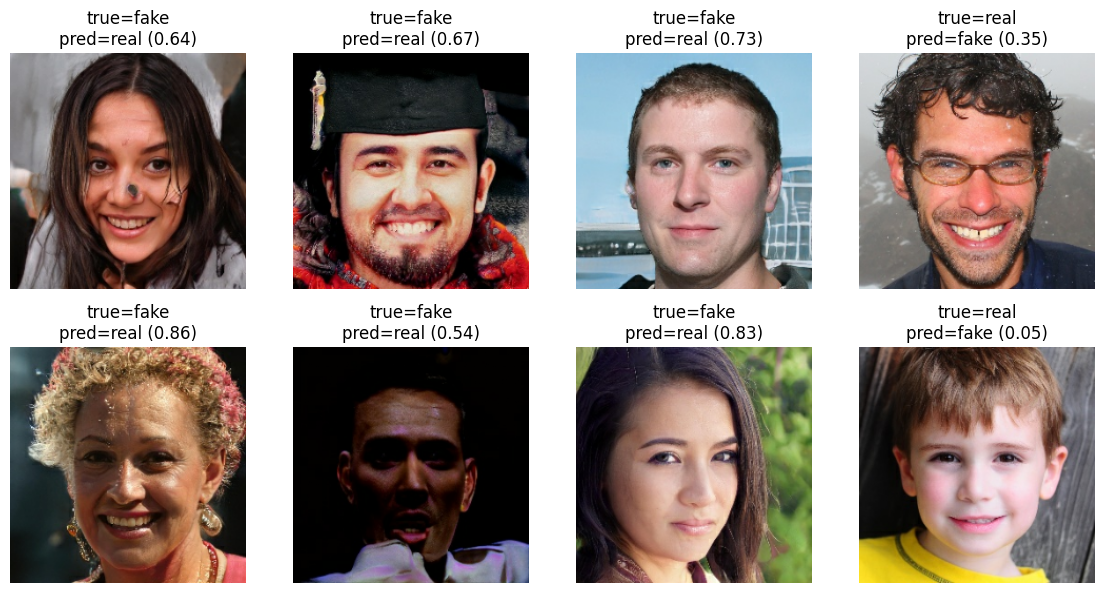

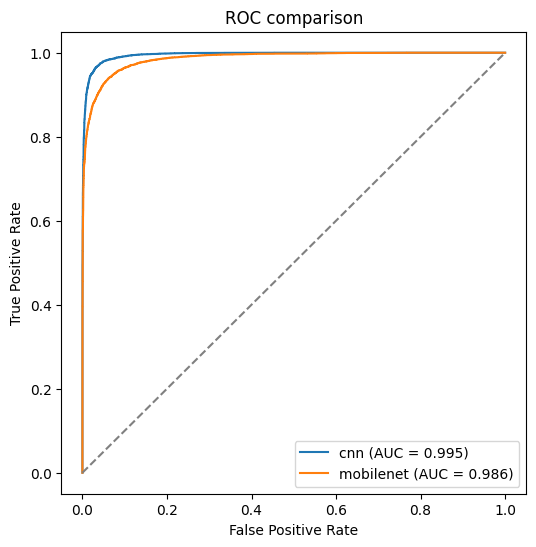

,model,accuracy,precision_real,recall_real,f1_real,auc,params,eval_time_s
0,cnn,0.96025,0.939463,0.9839,0.961168,0.995005,423361,72.1
1,mobilenet,0.93840,0.936479,0.9406,0.938535,0.985766,2259265,122.6


In [14]:
# Only evaluates whichever model(s) have been trained so far, so this works right
# after the CNN alone, and again later once MobileNetV2 is also trained.

results = []
if "cnn_model" in globals():
    t0 = time.time()
    results.append(evaluate_model("cnn", cnn_model, cnn_test_ds))
    results[-1]["eval_time_s"] = round(time.time() - t0, 1)

if "mobilenet_model" in globals():
    t0 = time.time()
    results.append(evaluate_model("mobilenet", mobilenet_model, tl_test_ds))
    results[-1]["eval_time_s"] = round(time.time() - t0, 1)

rows = [{k: r[k] for k in ("model", "accuracy", "precision_real", "recall_real", "f1_real",
                            "auc", "params", "eval_time_s")} for r in results]
comparison_df = pd.DataFrame(rows)
comparison_df.to_csv(os.path.join(METRICS_DIR, "model_comparison.csv"), index=False)

headers = list(comparison_df.columns)
md_lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
for _, row in comparison_df.iterrows():
    md_lines.append("| " + " | ".join(str(v) for v in row) + " |")
with open(os.path.join(METRICS_DIR, "model_comparison.md"), "w") as f:
    f.write("\n".join(md_lines))

fig, ax = plt.subplots(figsize=(6, 6))
for r in results:
    ax.plot(r["fpr"], r["tpr"], label=f"{r['model']} (AUC = {r['auc']:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC comparison"); ax.legend()
fig.savefig(os.path.join(FIGURES_DIR, "roc_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

comparison_df


## 10. Grad-CAM explanations

Shows which regions each model relies on for 3 real + 3 fake test images (original /
heatmap / overlay), using `Conv_1` for MobileNetV2 and the last `Conv2D` layer for the CNN.


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_1']
Received: inputs=Tensor(shape=(1, 128, 128, 3))
  warnings.warn(msg)


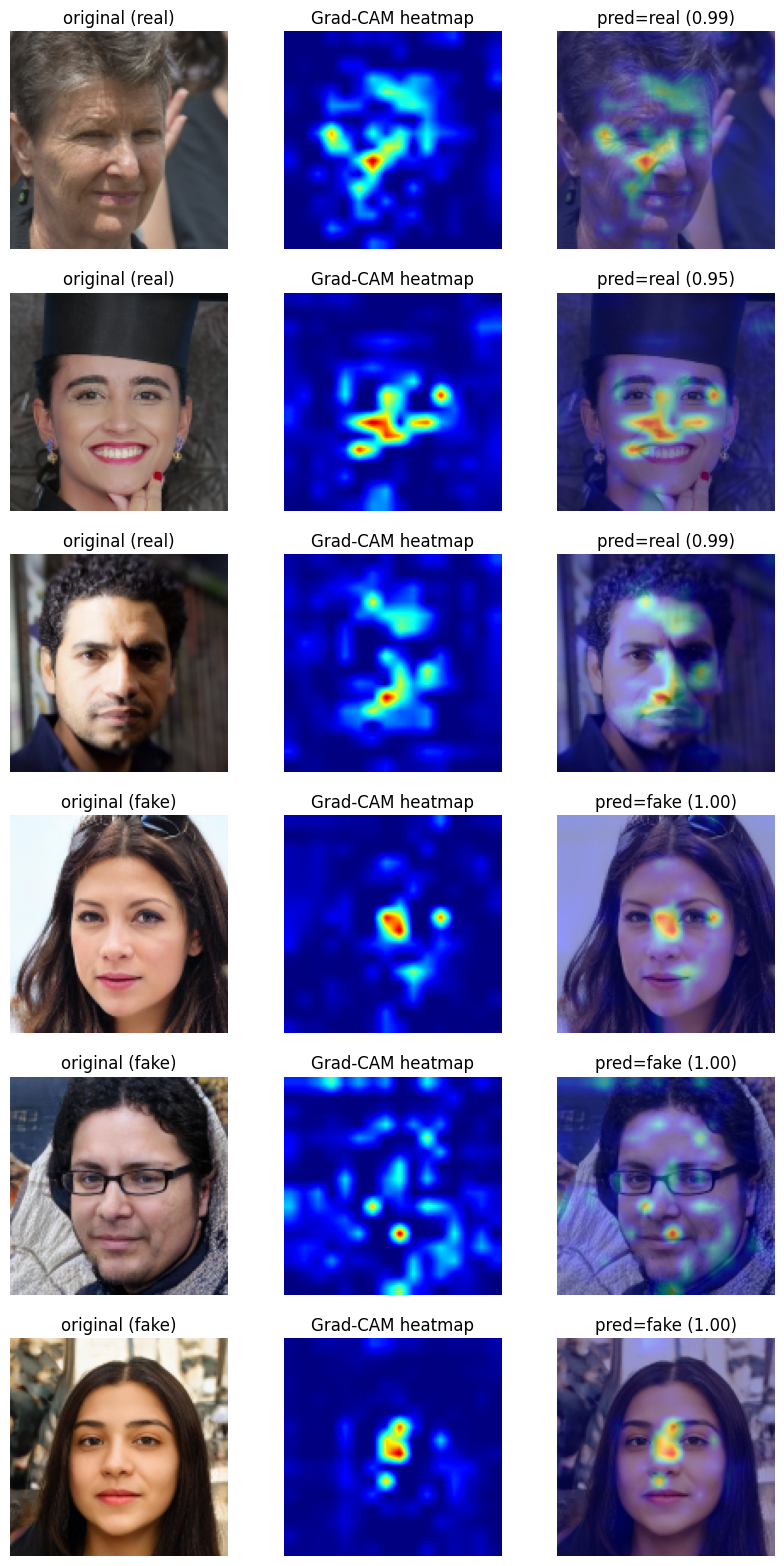

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_2']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


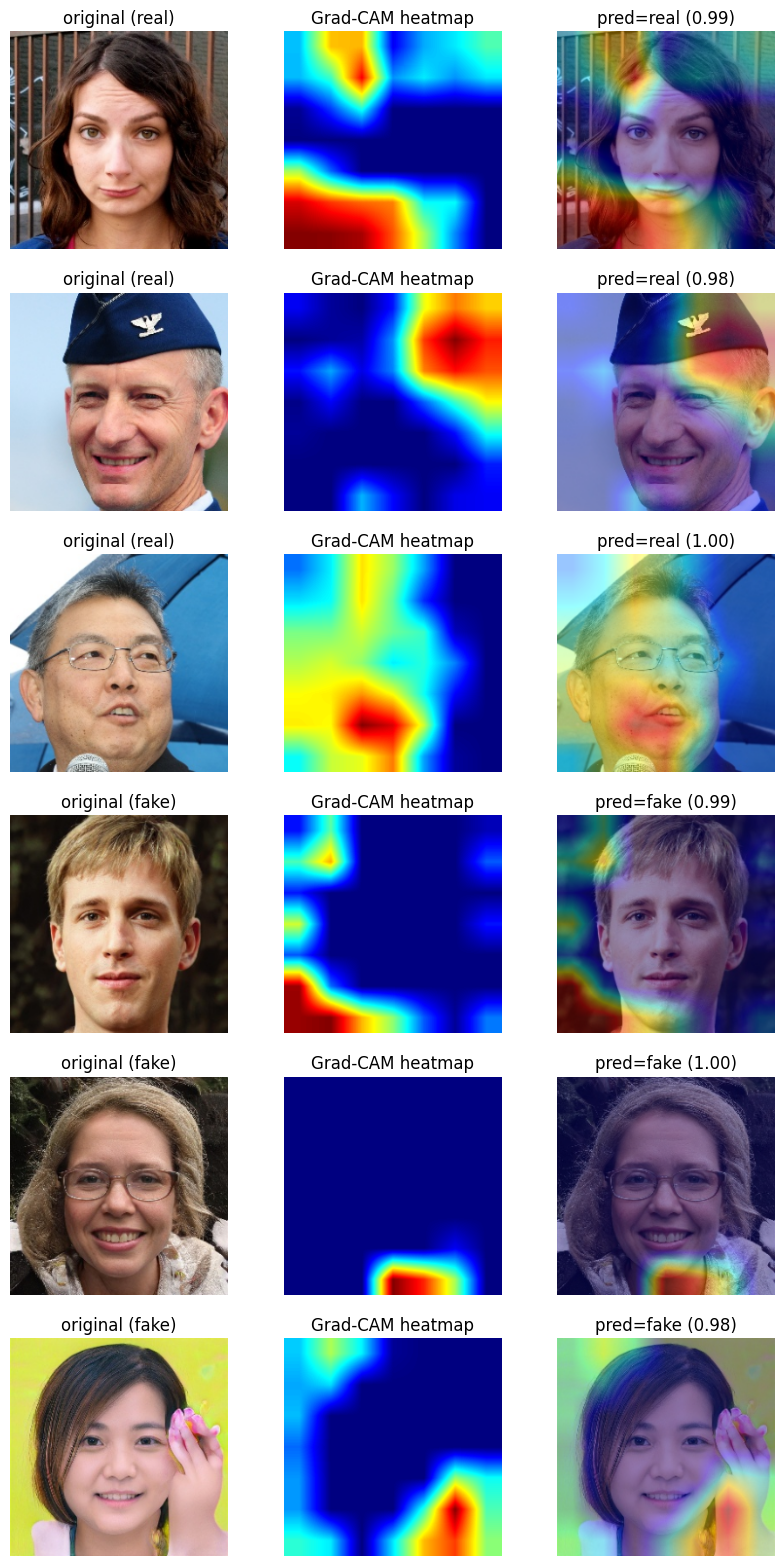

In [15]:
def find_last_conv_layer(model):
    if model.name == "mobilenet_v2_tl":
        return "Conv_1"
    for layer in reversed(model.layers):
        if isinstance(layer, layers.Conv2D):
            return layer.name
    raise ValueError("No Conv2D layer found")


def make_gradcam_overlay(model, img_array, layer_name=None):
    if layer_name is None:
        layer_name = find_last_conv_layer(model)
    grad_model = kmodels.Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    x = np.expand_dims(img_array.astype("float32"), axis=0)
    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(x)
        loss = predictions[:, 0]
    grads = tape.gradient(loss, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    heatmap = heatmap.numpy()
    h, w = img_array.shape[0], img_array.shape[1]
    heatmap_resized = cv2.resize(heatmap, (w, h))
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    base_img = img_array.astype(np.uint8)
    overlay = cv2.addWeighted(base_img, 0.6, heatmap_color, 0.4, 0)
    return heatmap_color, overlay


def gradcam_figure(name, model, img_size):
    samples = []
    for cls in ("real", "fake"):
        folder = os.path.join(DATA_DIR, "test", cls)
        for f in random.sample(os.listdir(folder), 3):
            samples.append((os.path.join(folder, f), cls))

    fig, axes = plt.subplots(len(samples), 3, figsize=(10, 3.3 * len(samples)))
    for row, (path, true_label) in enumerate(samples):
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, img_size).astype(np.float32)
        heatmap, overlay = make_gradcam_overlay(model, img)
        prob_real = float(model.predict(np.expand_dims(img, 0), verbose=0)[0, 0])
        pred_label = "real" if prob_real >= 0.5 else "fake"
        confidence = prob_real if pred_label == "real" else 1 - prob_real
        axes[row, 0].imshow(img.astype(np.uint8)); axes[row, 0].set_title(f"original ({true_label})")
        axes[row, 1].imshow(heatmap); axes[row, 1].set_title("Grad-CAM heatmap")
        axes[row, 2].imshow(overlay); axes[row, 2].set_title(f"pred={pred_label} ({confidence:.2f})")
        for ax in axes[row]:
            ax.axis("off")
    fig.savefig(os.path.join(FIGURES_DIR, f"{name}_gradcam.png"), dpi=150, bbox_inches="tight")
    plt.show()


if "cnn_model" in globals():
    gradcam_figure("cnn", cnn_model, CNN_IMG_SIZE)
if "mobilenet_model" in globals():
    gradcam_figure("mobilenet", mobilenet_model, TL_IMG_SIZE)


## 11. Gradio demo

Launches the demo with a public `share=True` link (Colab has no local browser access).
Uses whichever model scored higher on test accuracy above.


In [16]:
import gradio as gr

best_name = max(results, key=lambda r: r["accuracy"])["model"]
best_model = mobilenet_model if best_name == "mobilenet" else cnn_model
best_img_size = TL_IMG_SIZE if best_name == "mobilenet" else CNN_IMG_SIZE
print("Using", best_name, "for the demo")


def predict(image):
    if image is None:
        return None, None
    img = cv2.resize(image, best_img_size).astype(np.float32)
    prob_real = float(best_model.predict(np.expand_dims(img, 0), verbose=0)[0, 0])
    labels = {"Real": prob_real, "AI-Generated": 1 - prob_real}
    _, overlay = make_gradcam_overlay(best_model, img)
    return labels, overlay


demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(label="Upload a face image"),
    outputs=[gr.Label(label="Prediction"), gr.Image(label="Grad-CAM overlay")],
    title="Real vs AI-Generated Face Detection",
    description=(
        "Upload a face photo to see whether it looks real or AI-generated (StyleGAN), "
        "with a Grad-CAM explanation.\n\n"
        "Trained on StyleGAN faces; works best on front-facing face photos."
    ),
)
demo.launch(share=True)


Using cnn for the demo
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://41e62f163162b04953.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Bring results back to the local repo

Zip the trained models and outputs so you can download them and drop them into your local
`ai-face-detector/models/` and `ai-face-detector/outputs/` folders.


In [18]:
import shutil

shutil.make_archive("/content/models", "zip", MODELS_DIR)
shutil.make_archive("/content/outputs", "zip", os.path.join(DRIVE_DIR, "outputs"))

from google.colab import files
files.download("/content/models.zip")
files.download("/content/outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>